In [131]:
import pandas as pd
import requests, json
import matplotlib.pyplot as plt

In [87]:
data = []
count = 3
offset = 0
while count > 0:
    response = requests.get(
        "https://api.restcountries.com/countries/v5",
        headers={"Authorization": f"Bearer rc_live_7758de5a6412468aaf6168642ecc15ee"},
        params={
            "response_fields": (
                "names.common,region,population,area.kilometers,"
                "languages,currencies,borders"
            ),
            "limit": 100,
            "offset": offset,
        },
        timeout=30,
    )
    response.raise_for_status()

    page = response.json()["data"]
    data.extend(page["objects"])

    offset += 100
    count -= 1

In [39]:
with open("raw_data.json", "w") as f:
    json.dump(data, f)

In [40]:
rows = []
for country in data:
    lang = []
    for l in country['languages']:
        lang.append(l["name"])

    curr_codes = []
    for curr in country['currencies']:
        curr_codes.append(curr["code"])

    rows.append({
        "CountryName": country["names"]["common"],
        "Region": country["region"],
        "Area(km2)": country["area"]["kilometers"],
        "Languages": ", ".join(lang),
        "CurrencyCodes": ", ".join(curr_codes),
        "borders": ", ".join(country["borders"]),
        "Population": country["population"],
    })

df = pd.DataFrame(rows)

In [41]:
df

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
0,Abkhazia,Asia,8665.0,"Abkhaz, Russian",RUB,"GEO, RUS",244236
1,Afghanistan,Asia,652230.0,"Dari, Pashto, Turkmen",AFN,"IRN, PAK, TKM, UZB, TJK, CHN",43844000
2,Albania,Europe,28748.0,Albanian,ALL,"MNE, GRC, MKD, UNK",2335930
3,Algeria,Africa,2381741.0,Arabic,DZD,"TUN, LBY, NER, ESH, MRT, MLI, MAR",47400000
4,American Samoa,Oceania,199.0,"English, Samoan",USD,,43268
...,...,...,...,...,...,...,...
249,Western Sahara,Africa,266000.0,"Hassaniya Arabic, Spanish","DZD, MAD, MRU","DZA, MRT, MAR",510713
250,Yemen,Asia,527968.0,Arabic,YER,"OMN, SAU",32684503
251,Zambia,Africa,752612.0,English,ZMW,"AGO, BWA, COD, MWI, MOZ, NAM, TZA, ZWE",23003214
252,Zimbabwe,Africa,390757.0,"Barwe, English, Kalanga, Khoisan languages, Nd...","USD, ZWG","BWA, MOZ, ZAF, ZMB",16175966


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CountryName    254 non-null    object 
 1   Region         254 non-null    object 
 2   Area(km2)      254 non-null    float64
 3   Languages      254 non-null    object 
 4   CurrencyCodes  254 non-null    object 
 5   borders        254 non-null    object 
 6   Population     254 non-null    int64  
dtypes: float64(1), int64(1), object(5)
memory usage: 14.0+ KB


In [49]:
df.isna().sum()

CountryName      0
Region           0
Area(km2)        0
Languages        0
CurrencyCodes    0
borders          0
Population       0
dtype: int64

In [50]:
df[df["borders"] == ""]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
4,American Samoa,Oceania,199.0,"English, Samoan",USD,,43268
7,Anguilla,Americas,91.0,English,XCD,,16010
8,Antarctica,Antarctic,14000000.0,,,,1300
9,Antigua and Barbuda,Americas,442.0,English,XCD,,106365
12,Aruba,Americas,180.0,"Dutch, Papiamento",AWG,,110625
...,...,...,...,...,...,...,...
240,United States Minor Outlying Islands,Americas,34.2,English,USD,,300
241,United States Virgin Islands,Americas,347.0,English,USD,,87146
244,Vanuatu,Oceania,12189.0,"Bislama, English, French",VUV,,321409
248,Wallis and Futuna,Oceania,142.0,French,XPF,,11151


In [53]:
df["Area(km2)"].describe()

count    2.540000e+02
mean     5.917312e+05
std      1.895959e+06
min      4.400000e-01
25%      1.439750e+03
50%      6.297900e+04
75%      3.534238e+05
max      1.709824e+07
Name: Area(km2), dtype: float64

In [54]:
df["Population"].describe()

count    2.540000e+02
mean     3.177917e+07
std      1.314092e+08
min      0.000000e+00
25%      2.220078e+05
50%      4.920816e+06
75%      2.054057e+07
max      1.429404e+09
Name: Population, dtype: float64

In [58]:
df["Region"].value_counts()

Region
Africa       60
Americas     56
Europe       54
Asia         52
Oceania      27
Antarctic     5
Name: count, dtype: int64

In [110]:
desc2 = df["Population"].describe()
Q1 = desc2["25%"]
Q3 = desc2["75%"]
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
num_of_outliers = len(df[(df["Population"] < lower) | (df["Population"] > upper)])

num_of_outliers

30

In [113]:
df[(df["Population"] < lower) | (df["Population"] > upper)]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
18,Bangladesh,Asia,147570.0,Bengali,BDT,"MMR, IND",169828911
30,Brazil,Americas,8515767.0,Portuguese,BRL,"ARG, BOL, COL, GUF, GUY, PRY, PER, SUR, URY, VEN",214211951
46,China,Asia,9706961.0,Chinese,CNY,"AFG, BTN, MMR, HKG, IND, KAZ, NPL, PRK, KGZ, L...",1404890000
49,Colombia,Americas,1141748.0,Spanish,COP,"BRA, ECU, PAN, PER, VEN",53399171
59,DRC,Africa,2344858.0,"French, Kongo, Lingala, Luba-Lulua, Swahili",CDF,"AGO, BDI, CAF, COG, RWA, SSD, TZA, UGA, ZMB",116452000
65,Egypt,Africa,1002450.0,Arabic,EGP,"ISR, LBY, PSE, SDN",108613296
71,Ethiopia,Africa,1104300.0,Amharic,ETB,"DJI, ERI, KEN, SOM, SSD, SDN",111652998
76,France,Europe,551695.0,French,EUR,"AND, BEL, DEU, ITA, LUX, MCO, ESP, CHE",69081996
83,Germany,Europe,357114.0,German,EUR,"AUT, BEL, CZE, DNK, FRA, LUX, NLD, POL, CHE",83298787
102,India,Asia,3287590.0,"English, Hindi, Tamil",INR,"BGD, BTN, MMR, CHN, NPL, PAK",1429404000


In [115]:
desc1 = df["Area(km2)"].describe()
Q1 = desc1["25%"]
Q3 = desc1["75%"]
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
num_of_outliers = len(df[(df["Area(km2)"] < lower) | (df["Area(km2)"] > upper)])

num_of_outliers

35

In [118]:
df[(df["Area(km2)"] < lower) | (df["Area(km2)"] > upper)]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
3,Algeria,Africa,2381741.0,Arabic,DZD,"TUN, LBY, NER, ESH, MRT, MLI, MAR",47400000
6,Angola,Africa,1246700.0,Portuguese,AOA,"COG, COD, ZMB, NAM",38778554
8,Antarctica,Antarctic,14000000.0,,,,1300
10,Argentina,Americas,2780400.0,"Guarani, Spanish",ARS,"BOL, BRA, CHL, PRY, URY",46466688
13,Australia,Oceania,7692024.0,English,AUD,,27921150
26,Bolivia,Americas,1098581.0,"Aymara, Guarani, Quechua, Spanish",BOB,"ARG, BRA, CHL, PRY, PER",11365333
30,Brazil,Americas,8515767.0,Portuguese,BRL,"ARG, BOL, COL, GUF, GUY, PRY, PER, SUR, URY, VEN",214211951
40,Canada,Americas,9984670.0,"English, French",CAD,"USA, GRL",41798407
44,Chad,Africa,1284000.0,"Arabic, French",XAF,"CMR, CAF, LBY, NER, NGA, SDN",20031602
46,China,Asia,9706961.0,Chinese,CNY,"AFG, BTN, MMR, HKG, IND, KAZ, NPL, PRK, KGZ, L...",1404890000


In [68]:
len(df[df.duplicated()])

0

In [69]:
df[df["Area(km2)"] < 0]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population


In [70]:
df[df["Area(km2)"] == 0]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population


In [71]:
df[df["Population"] <= 0]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
29,Bouvet Island,Antarctic,49.0,Norwegian,,,0
97,Heard Island and McDonald Islands,Antarctic,412.0,English,,,0


In [72]:
df[df["Languages"] == ""]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
8,Antarctica,Antarctic,14000000.0,,,,1300


In [73]:
df[df["CurrencyCodes"] == ""]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
8,Antarctica,Antarctic,14000000.0,,,,1300
29,Bouvet Island,Antarctic,49.0,Norwegian,,,0
97,Heard Island and McDonald Islands,Antarctic,412.0,English,,,0


In [80]:
df.loc[df["CountryName"] == "Bouvet Island", "CurrencyCodes"] = "NOK"

In [82]:
df.loc[df["CountryName"] == "Bouvet Island"]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
29,Bouvet Island,Antarctic,49.0,Norwegian,NOK,,0


In [83]:
df.loc[df["CountryName"] == "Heard Island and McDonald Islands", "CurrencyCodes"] = "AUD"

In [84]:
df.loc[df["CountryName"] == "Heard Island and McDonald Islands"]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
97,Heard Island and McDonald Islands,Antarctic,412.0,English,AUD,,0


In [85]:
df[df["CurrencyCodes"] == ""]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
8,Antarctica,Antarctic,14000000.0,,,,1300


In [91]:
missing_keys = 0
empty_list = 0
missing = 0

for country in data:
    if "borders" not in country:
        missing_keys += 1
    elif country["borders"] == []:
        empty_list += 1
    elif country["borders"] is None:
        missing += 1

print(f"Missing keys = {missing_keys}\nEmpty Lists = {empty_list}\nMissing values = {missing}")

Missing keys = 0
Empty Lists = 86
Missing values = 0


In [95]:
df[df["borders"] == ""]["CountryName"].tolist()

['American Samoa',
 'Anguilla',
 'Antarctica',
 'Antigua and Barbuda',
 'Aruba',
 'Australia',
 'Bahamas',
 'Bahrain',
 'Barbados',
 'Bermuda',
 'Bouvet Island',
 'British Indian Ocean Territory',
 'British Virgin Islands',
 'Cabo Verde',
 'Caribbean Netherlands',
 'Cayman Islands',
 'Christmas Island',
 'Cocos (Keeling) Islands',
 'Comoros',
 'Cook Islands',
 'Cuba',
 'Curaçao',
 'Cyprus',
 'Dominica',
 'Falkland Islands',
 'Faroe Islands',
 'Fiji',
 'French Polynesia',
 'French Southern and Antarctic Lands',
 'Greenland',
 'Grenada',
 'Guadeloupe',
 'Guam',
 'Guernsey',
 'Heard Island and McDonald Islands',
 'Iceland',
 'Isle of Man',
 'Jamaica',
 'Japan',
 'Jersey',
 'Kiribati',
 'Madagascar',
 'Maldives',
 'Malta',
 'Marshall Islands',
 'Martinique',
 'Mauritius',
 'Mayotte',
 'Micronesia',
 'Montserrat',
 'Naoero',
 'New Caledonia',
 'New Zealand',
 'Niue',
 'Norfolk Island',
 'Northern Mariana Islands',
 'Palau',
 'Philippines',
 'Pitcairn Islands',
 'Puerto Rico',
 'Réunion',
 '

In [103]:
df.loc[df["CountryName"] == "Greenland", "borders"] = "CAN"
df.loc[df["CountryName"] == "Cyprus", "borders"] = "GBR"
df.loc[df["CountryName"] == "Åland Islands", "borders"] = "SWE"
df.loc[df["CountryName"] == "Canada", "borders"] = "USA, GRL"

In [97]:
len(df[df["borders"] == ""])

83

In [104]:
df[df["CountryName"] == "Canada"]

,CountryName,Region,Area(km2),Languages,CurrencyCodes,borders,Population
40,Canada,Americas,9984670.0,"English, French",CAD,"USA, GRL",41798407


In [119]:
df.to_csv("cleaned.csv", index=False)

In [123]:
names = df["Region"].unique()

In [130]:
region_population = {}
for n in names:
    region_population[n] = df[df["Region"] == n]["Population"].sum()

region_population

{'Asia': np.int64(4748373354),
 'Europe': np.int64(738487195),
 'Africa': np.int64(1489812112),
 'Oceania': np.int64(48148773),
 'Americas': np.int64(1047086413),
 'Antarctic': np.int64(1732)}

Which region has the highest total population?


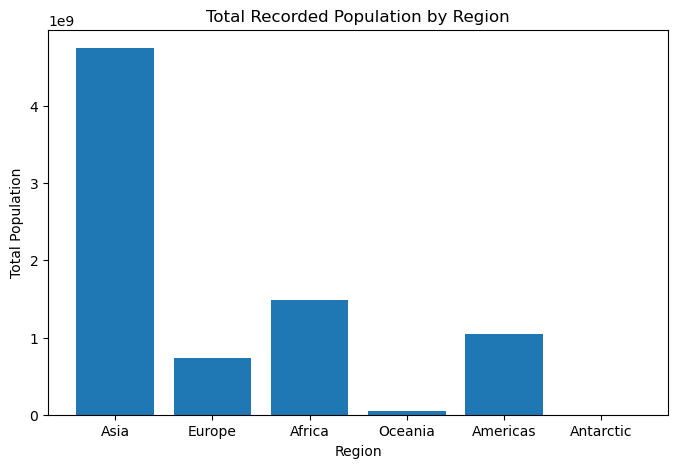

Asia has the highest total recorded population in the dataset, at approximately 4.75 billion, followed by Africa at 1.49 billion


In [136]:
print("Which region has the highest total population?")

regions = region_population.keys()
populations = region_population.values()

plt.figure(figsize=(8, 5))
plt.bar(regions, populations)
plt.title("Total Recorded Population by Region")
plt.xlabel("Region")
plt.ylabel("Total Population")
plt.show()

print("Asia has the highest total recorded population in the dataset, at approximately 4.75 billion, followed by Africa at 1.49 billion")

Which region has the highest number of records?


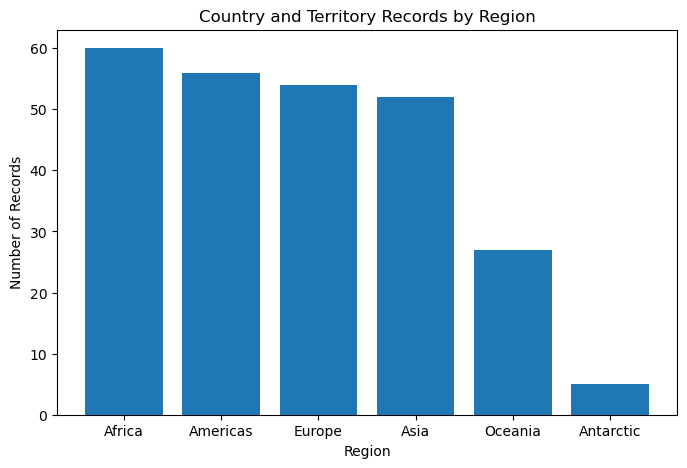

This chart shows the number of country and territory records in each region. Africa has the most records (60), followed by the Americas (56), while the Antarctic region has the fewest (5).


In [156]:
print("Which region has the highest number of records?")

value_counts = df["Region"].value_counts()
regions = value_counts.index
rows = value_counts.tolist()

plt.figure(figsize=(8, 5))
plt.bar(regions, rows)
plt.title("Country and Territory Records by Region")
plt.xlabel("Region")
plt.ylabel("Number of Records")
plt.show()

print("This chart shows the number of country and territory records in each region. Africa has the most records (60), followed by the Americas (56), while the Antarctic region has the fewest (5).")

How are the population sizes of countries and territories distributed in the dataset?


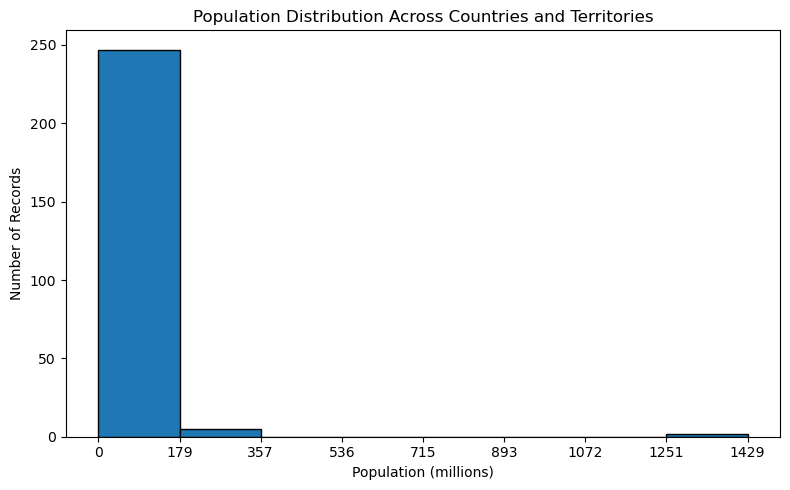

The histogram groups countries and territories by population size. Of the 254 records, 247 fall in the first interval, from 0 to about 178.68 million  people. Only two records fall in the highest interval, from about 1.25 to 1.43 billion people


In [173]:
print("How are the population sizes of countries and territories distributed in the dataset?")

population_millions = df["Population"] / 1000000

plt.figure(figsize=(8, 5))

_, bin_edges, _ = plt.hist(population_millions, bins=8, edgecolor="black")

plt.xticks(bin_edges)
plt.title("Population Distribution Across Countries and Territories")
plt.xlabel("Population (millions)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("The histogram groups countries and territories by population size. Of the 254 records, 247 fall in the first interval, from 0 to about 178.68 million  people. Only two records fall in the highest interval, from about 1.25 to 1.43 billion people")

How do the median and spread of country and territory areas vary by region?


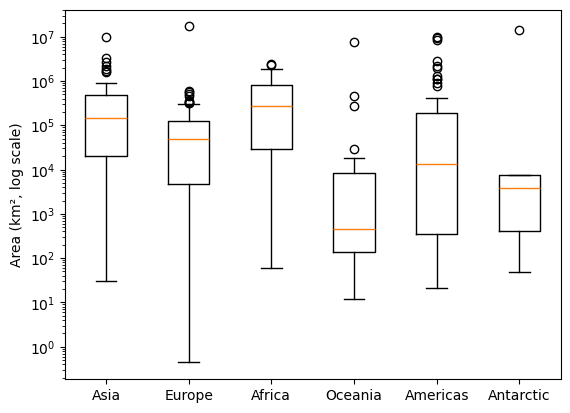

Each box shows the middle 50% of country and territory areas in a region, and the orange line marks the median. Africa has the highest median area,    while Oceania has the lowest. The Americas have the widest box on the logarithmic scale, showing the largest relative spread between the first and     third quartiles


In [203]:
print("How do the median and spread of country and territory areas vary by region?")

region_areas = {}

for region in df["Region"].unique():
    areas = df[df["Region"] == region]["Area(km2)"].tolist()
    region_areas[region] = areas

plt.boxplot(region_areas.values())
plt.xticks(range(1, len(region_areas) + 1), list(region_areas.keys()))
plt.yscale("log")
plt.ylabel("Area (km², log scale)")
plt.show()

print("Each box shows the middle 50% of country and territory areas in a region, and the orange line marks the median. Africa has the highest median area,    while Oceania has the lowest. The Americas have the widest box on the logarithmic scale, showing the largest relative spread between the first and     third quartiles")

Do countries and territories with larger areas tend to have larger populations?


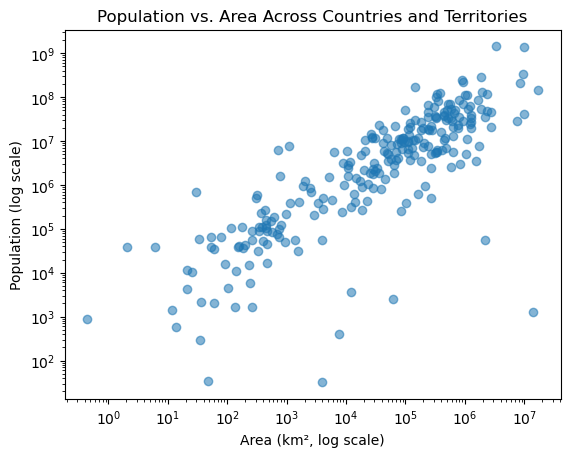

Each point represents a country or territory. The overall upward pattern shows that larger areas tend to be associated with larger populations,although records with similar areas can have very different population sizes. Both axes use a logarithmic scale. Two records with zero population were excluded from the plot because zero cannot be displayed on the logarithmic population axis.


In [201]:
print("Do countries and territories with larger areas tend to have larger populations?")
plot_data = df[df["Population"] > 0]

plt.scatter(plot_data["Area(km2)"], plot_data["Population"], alpha=0.55)
plt.xscale("log")
plt.yscale("log")
plt.title("Population vs. Area Across Countries and Territories")
plt.xlabel("Area (km², log scale)")
plt.ylabel("Population (log scale)")
plt.show()

print("Each point represents a country or territory. The overall upward pattern shows that larger areas tend to be associated with larger populations,although records with similar areas can have very different population sizes. Both axes use a logarithmic scale. Two records with zero population were excluded from the plot because zero cannot be displayed on the logarithmic population axis.")